# Wilson-Cowan Neural Network Simulation and Inference

This notebook demonstrates the robustness of the inference method to model-mismatch by generating synthetic data from a highly non-linear neural rate model (Wilson-Cowan) and successfully inferring its topology using the SDE-based global parameter MCMC engine.


In [1]:
import numpy as np
import networkx as nx
import graph_tool.all as gt
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy.special import expit
import sys
import os

sys.path.append(os.path.abspath('.'))
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import compute_reconstruction_metrics
from gene_expr import GeneExprBlockState

from inference_pipeline.inference.reconstruction_metrics import evaluate_topology, evaluate_weights


## 1. Simulate the Wilson-Cowan Network

We generate a 10-node directed Erdos-Renyi graph and simulate its dynamics using the Wilson-Cowan ODEs. We use 20 independent trials to simulate transient responses to stimuli, providing the inference algorithm with a rich dynamical dataset.


Simulating Wilson-Cowan Neural Network (N=10)...
Generated 570 transition pairs with dt=0.1


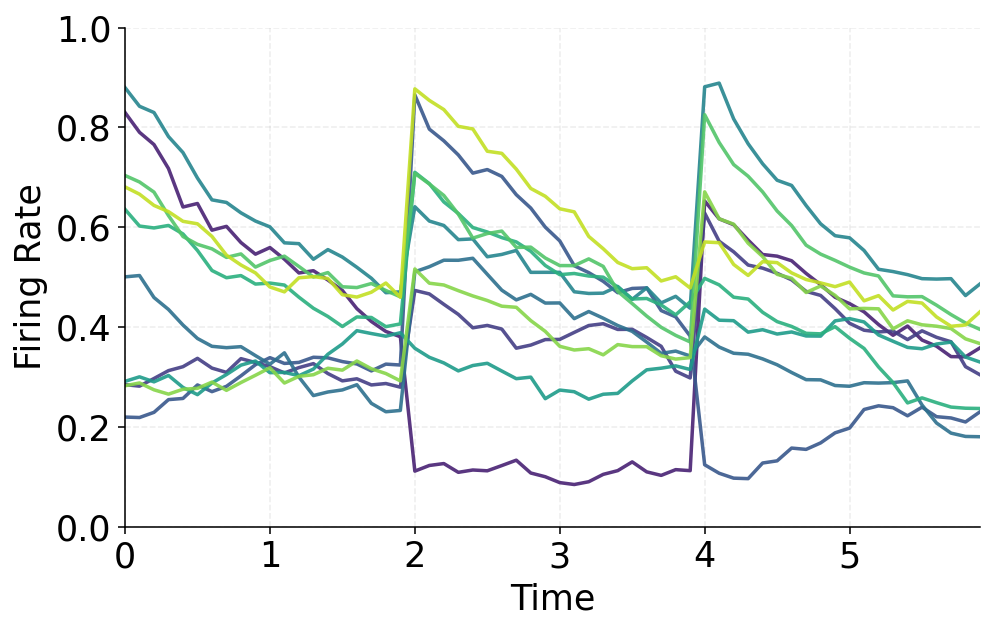

In [44]:
np.random.seed(42)
N = 10
p_edge = 0.15

# Generate Ground Truth Graph
G_true = nx.erdos_renyi_graph(n=N, p=p_edge, directed=True, seed=42)
W_true = nx.to_numpy_array(G_true)
# Randomly assign +3.0 (excitatory) or -3.0 (inhibitory) to edges
signs = np.random.choice([-1.0, 1.0], size=(N, N))
true_weights = np.random.uniform(0.5, 1.5, size=(N, N))
W_true = W_true * signs * true_weights

# Simulation parameters
tau = 2.0         
I = -1.5          
sigma = 0.05      # Low noise to preserve signal
dt_sim = 0.01
steps_per_trial = 200  # 5 time units per trial
num_trials = 30        # 20 different initial conditions
subsample = 10         # dt_infer = 0.1

print(f"Simulating Wilson-Cowan Neural Network (N={N})...")
pairs = []
trajectories = []

for trial in range(num_trials):
    x = np.random.uniform(0.1, 0.9, size=N)
    trial_traj = []
    
    for step in range(steps_per_trial):
        net_input = W_true @ x + I
        activation = expit(net_input)
        dx = (-x / tau + (1 - x) * activation) * dt_sim
        noise = sigma * np.sqrt(dt_sim) * np.random.randn(N)
        
        x = x + dx + noise
        x = np.clip(x, 0.01, 0.99)
        
        if step % subsample == 0:
            trial_traj.append(x.copy())
            
    # Add pairs for this trial
    for i in range(len(trial_traj) - 1):
        pairs.append(np.column_stack([trial_traj[i], trial_traj[i+1]]))
    trajectories.extend(trial_traj)

trajectories = np.array(trajectories)
dt_infer = dt_sim * subsample
print(f"Generated {len(pairs)} transition pairs with dt={dt_infer}")

# Transient trajectories plot (clean visual style for illustration)
n_plot = min(60, trajectories.shape[0])
t_plot = np.arange(n_plot) * dt_infer

fig, ax = plt.subplots(figsize=(7.2, 4.6), dpi=140)
colors = sns.color_palette("viridis", n_colors=trajectories.shape[1])
fontsize = 18

for idx, color in enumerate(colors):
    ax.plot(
        t_plot,
        trajectories[:n_plot, idx],
        color=color,
        alpha=0.9,
        lw=1.8
    )

ax.set_xlabel("Time", fontsize=fontsize)
ax.set_ylabel("Firing Rate", fontsize=fontsize)
ax.set_xlim(t_plot[0], t_plot[-1])
ax.set_ylim(0, 1.0)
ax.tick_params(axis="both", labelsize=fontsize)
ax.grid(True, linestyle="--", alpha=0.22)

sns.despine()
plt.tight_layout()
plt.show()


## 2. Run MCMC Inference

We now feed the dataset into the standard `GeneExprBlockState` engine. Even though the generating physics differ significantly from the internal SDE solver, we expect the engine to capture the primary topological constraints.


In [3]:
import random

g_init = gt.Graph(directed=True)
g_init.add_vertex(N)
g_init.add_edge(0, 1)

# Initial theta: [log(decay), log(V), log(noise)]
initial_theta = [np.log(1/tau), np.log(1.0), np.log(0.01)]

np.random.seed(42)
random.seed(42)
# try common graph-tool RNG seed APIs (compatibility across versions)
try:
    gt.seed_rng(42)
except Exception:
    try:
        gt.random.seed_rng(42)
    except Exception:
        pass

print("Initializing Inference Engine...")
state = GeneExprBlockState(pairs, dt=dt_infer, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta, self_loops=False)

print("Running Burn-in (100 sweeps)...")
state = run_burn_in(state, n_burnin=100, theta_mode="global", beta=1.0, seed=42)

print("Running Posterior Sampling (200 sweeps)...")
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=100, delta_k=1, theta_mode="global", beta=1.0, seed=42)

edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
W_inferred = W_ensemble[-1]

# save the results
results_dir = "results"
if not os.path.exists(results_dir):
    os.makedirs(results_dir)

Initializing Inference Engine...
Running Burn-in (100 sweeps)...

--- PHASE 1: Equilibration (100 sweeps) ---
Burn-in Sweep  1/100: Entropy = -13888.7405 (dS_topo = -5721.2956, dS_param = -722.3669, moves = 5231)
Burn-in Sweep 10/100: Entropy = -14032.4739 (dS_topo = -34.1883, dS_param = -18.1899, moves = 4551)
Burn-in Sweep 20/100: Entropy = -14037.1806 (dS_topo = -25.7641, dS_param =  -2.5161, moves = 5233)
Burn-in Sweep 30/100: Entropy = -14195.6436 (dS_topo = -40.1342, dS_param =  -0.5576, moves = 5599)
Burn-in Sweep 40/100: Entropy = -14241.4323 (dS_topo =   2.9502, dS_param =  -0.4762, moves = 5718)
Burn-in Sweep 50/100: Entropy = -14267.8170 (dS_topo =  -4.1031, dS_param =  -0.1806, moves = 5429)
Burn-in Sweep 60/100: Entropy = -14429.7861 (dS_topo =  18.8568, dS_param =  -0.1516, moves = 5862)
Burn-in Sweep 70/100: Entropy = -14404.5501 (dS_topo = -20.3357, dS_param =  -2.6973, moves = 6122)
Burn-in Sweep 80/100: Entropy = -14298.5762 (dS_topo = -56.1472, dS_param =  -1.0059, m

## 3. Evaluation and Metrics

Finally, we calculate the F1-Score, True Positive Rate, and Structural Hamming Distance to evaluate topological reconstruction, and visualize the true vs. inferred adjacency matrices.


--- RESULTS ---
F1-Score: 0.476
TPR (Recall): 0.385 | FPR: 0.039 | Precision: 0.625
SHD: 11
Sign Accuracy: 0.890
AUROC: 0.776 | AUPRC: 0.594


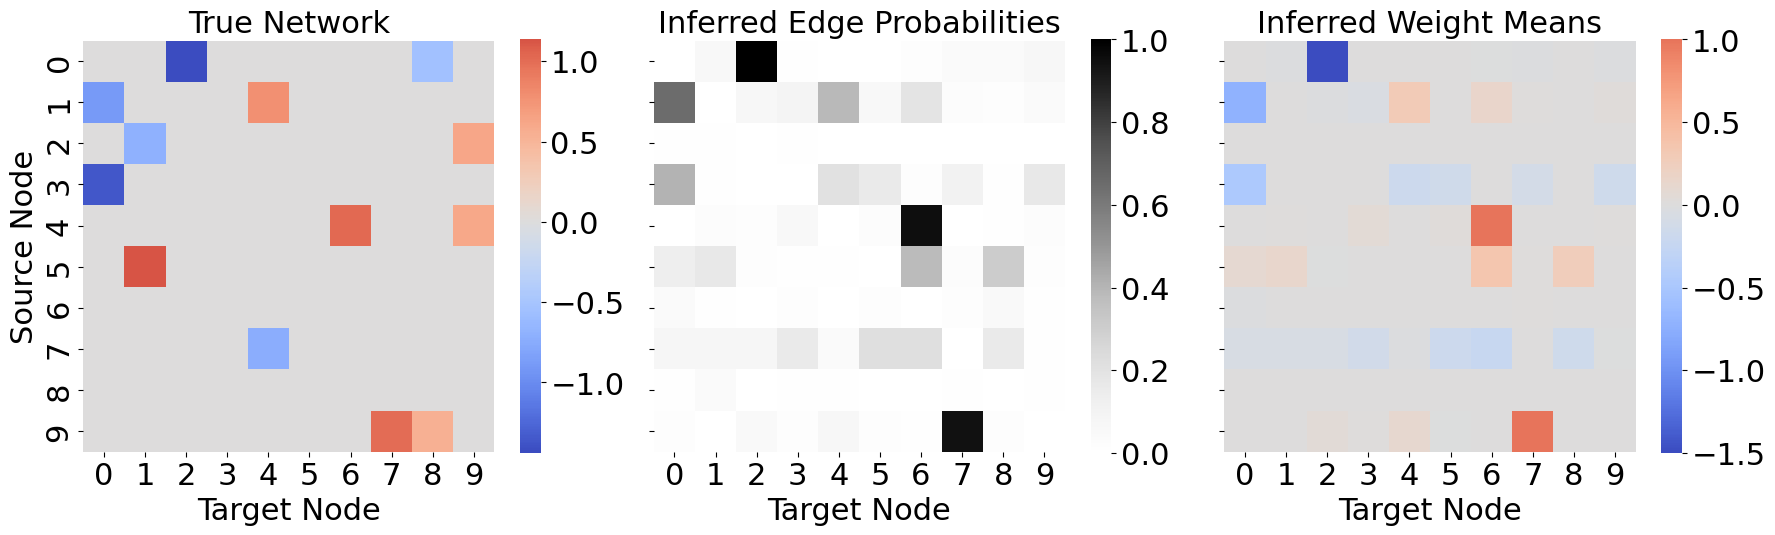

In [17]:
metrics = compute_reconstruction_metrics(W_true, W_inferred)
print("--- RESULTS ---")
print(f"F1-Score: {metrics['F1-Score']:.3f}")
print(f"TPR (Recall): {metrics['TPR (Recall)']:.3f} | FPR: {metrics['FPR']:.3f} | Precision: {metrics['Precision']:.3f}")
print(f"SHD: {metrics['SHD']}")
# sign accuracy
true_signs = np.sign(W_true)
inferred_signs = np.sign(W_inferred)
sign_accuracy = np.sum(true_signs == inferred_signs) / (N * N)
print(f"Sign Accuracy: {sign_accuracy:.3f}")
# compute AUROC, AUPRC
from sklearn.metrics import roc_auc_score, average_precision_score
true_edges = (W_true != 0).astype(int).flatten()
inferred_probs = edge_probabilities.flatten()
auroc = roc_auc_score(true_edges, inferred_probs)
auprc = average_precision_score(true_edges, inferred_probs)
print(f"AUROC: {auroc:.3f} | AUPRC: {auprc:.3f}")

# Plot Probability Matrix vs True Adjacency
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fontsize=22

ax0 = sns.heatmap(W_true, ax=axes[0], cmap="coolwarm", cbar=True, square=True, center=0)
# adjust colorbar fontsize
cbar = ax0.collections[0].colorbar
cbar.ax.tick_params(labelsize=fontsize)
axes[0].set_title("True Network", fontsize=fontsize)
axes[0].tick_params(axis='both', which='major', labelsize=fontsize)
axes[0].set_xlabel("Target Node", fontsize=fontsize)
axes[0].set_ylabel("Source Node", fontsize=fontsize)

ax1 = sns.heatmap(edge_probabilities, ax=axes[1], cmap="Greys", vmin=0, vmax=1.0, square=True)
# adjust colorbar fontsize
cbar = ax1.collections[0].colorbar
cbar.ax.tick_params(labelsize=fontsize)
axes[1].set_title("Inferred Edge Probabilities", fontsize=fontsize)
axes[1].tick_params(axis='both', which='major', labelsize=fontsize)
axes[1].set_xlabel("Target Node", fontsize=fontsize)
axes[1].set_yticks(np.arange(0.5, N, 1), labels=[])
#axes[1].set_ylabel("Source Node", fontsize=fontsize)

# Plot Weight Mean vs True Weights
ax2 = sns.heatmap(weight_mean*edge_probabilities, cmap="coolwarm", square=True, center=0, ax=axes[2], vmin=-1.5, vmax=1.0)
# adjust colorbar fontsize
cbar = ax2.collections[0].colorbar
cbar.ax.tick_params(labelsize=fontsize)
axes[2].set_title("Inferred Weight Means", fontsize=fontsize)
axes[2].set_xlabel("Target Node", fontsize=fontsize)
axes[2].tick_params(axis='both', which='major', labelsize=fontsize)
axes[2].set_yticks(np.arange(0.5, N, 1), labels=[])
#axes[2].set_ylabel("Source Node", fontsize=fontsize)


plt.tight_layout()
plt.show()


In [30]:

from scipy.integrate import odeint
from scipy.stats import spearmanr

def wc_deriv(x, t, W, I_ext, tau_val):
    net_input = W @ x + I_ext
    # Ensure dimensions match
    return -x / tau_val + (1 - x) * expit(net_input)

t_span = np.linspace(0, 100, 500)
x0 = np.full(N, 0.5)

# Unperturbed I
I_ext_unpert = np.full(N, I)

# Perturbed I (Overexpress node 0)
ko_idx = 0
I_ext_pert = I_ext_unpert.copy()
I_ext_pert[ko_idx] += 5.0

# 1. True system response
true_unpert_traj = odeint(wc_deriv, x0, t_span, args=(W_true, I_ext_unpert, tau))
true_unpert = true_unpert_traj[-1]

true_pert_traj = odeint(wc_deriv, true_unpert, t_span, args=(W_true, I_ext_pert, tau))
true_pert = true_pert_traj[-1]
delta_true = true_pert - true_unpert

# 2. Ensemble prediction
N_ens = len(W_ensemble)
delta_inferred = np.zeros((N_ens, N))
stat_inferred_pert = np.zeros((N_ens, N))

for i, W_s in enumerate(W_ensemble):
    # For inference, the tau parameter is absorbed in theta. 
    # But wait, in the notebook, theta_ensemble is also collected. 
    # Let's use the tau from theta_ensemble[i].
    # theta[0] = log(1/tau) -> tau = exp(-theta[0])
    tau_s = np.exp(-theta_ensemble[i][0])
    
    unpert_traj = odeint(wc_deriv, x0, t_span, args=(W_s, I_ext_unpert, tau_s))
    unpert_ss = unpert_traj[-1]
    
    pert_traj = odeint(wc_deriv, unpert_ss, t_span, args=(W_s, I_ext_pert, tau_s))
    pert_ss = pert_traj[-1]
    
    stat_inferred_pert[i] = pert_ss
    delta_inferred[i] = pert_ss - unpert_ss

mean_delta_inf = delta_inferred.mean(axis=0)

# 3. MAP prediction (we use the last sample, which was assigned to W_inferred)
best_idx = -1
best_delta_inf = delta_inferred[best_idx]

# Mask the perturbed node for evaluation
mask = np.ones(N, dtype=bool)
mask[ko_idx] = False

spearman_best, _ = spearmanr(delta_true[mask], best_delta_inf[mask])
spearman_ens, _ = spearmanr(delta_true[mask], mean_delta_inf[mask])


min_val = min(delta_true[mask].min(), mean_delta_inf[mask].min(), best_delta_inf[mask].min()) - 0.05
max_val = max(delta_true[mask].max(), mean_delta_inf[mask].max(), best_delta_inf[mask].max()) + 0.05


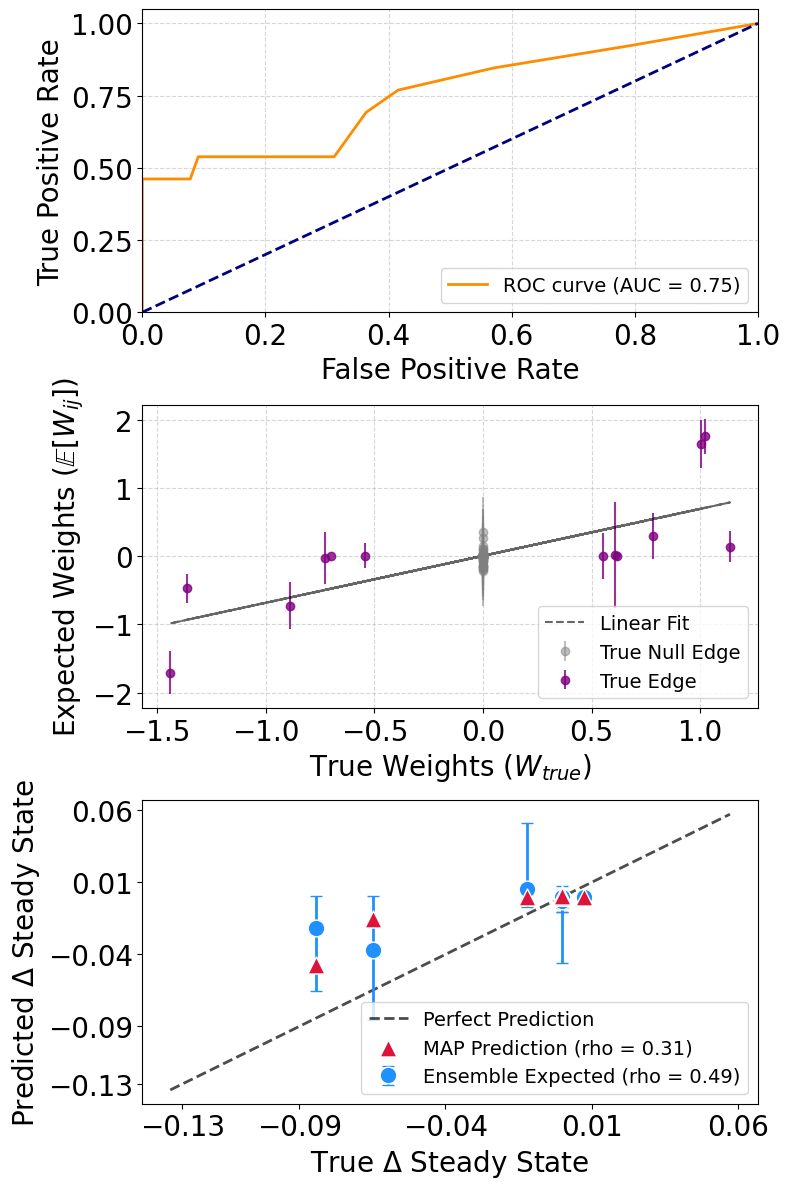

In [41]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from scipy.stats import pearsonr, spearmanr

N = W_true.shape[0]
mask = ~np.eye(N, dtype=bool)
y_true_binary = (W_true[mask] != 0).astype(int)
y_scores = edge_probabilities[mask]
fpr, tpr, _ = roc_curve(y_true_binary, y_scores)
roc_auc = auc(fpr, tpr)

_, [ax_roc, ax_corr, ax] = plt.subplots(3,1,figsize=(8, 12))
fontsize=20


ax_roc.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
ax_roc.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('False Positive Rate', fontsize=fontsize)
ax_roc.set_ylabel('True Positive Rate', fontsize=fontsize)
#ax_roc.set_title('Structural Recovery\n(ROC Curve)', fontsize=fontsize)
ax_roc.tick_params(axis='both', which='major', labelsize=fontsize)
ax_roc.legend(loc="lower right", fontsize=fontsize-6)
ax_roc.grid(True, linestyle='--', alpha=0.5)

x_vals = W_true[mask]
expected_weights = weight_mean * edge_probabilities
y_vals = expected_weights[mask]
y_errs = weight_std[mask]

pr, _ = pearsonr(x_vals, y_vals)
sr, _ = spearmanr(x_vals, y_vals)

true_edge_mask = (x_vals != 0)
ax_corr.errorbar(x_vals[~true_edge_mask], y_vals[~true_edge_mask], yerr=y_errs[~true_edge_mask], fmt='o', color='gray', alpha=0.5, label='True Null Edge')
ax_corr.errorbar(x_vals[true_edge_mask], y_vals[true_edge_mask], yerr=y_errs[true_edge_mask], fmt='o', color='purple', alpha=0.8, label='True Edge')

m, b = np.polyfit(x_vals, y_vals, 1)
ax_corr.plot(x_vals, m*x_vals + b, color='black', linestyle='--', alpha=0.6, label='Linear Fit')

#ax_corr.set_title(f"Weight Recovery\nPearson $\\rho$={pr:.2f}, Spearman $r$={sr:.2f}", fontsize=fontsize)
ax_corr.set_xlabel("True Weights ($W_{true}$)", fontsize=fontsize)
ax_corr.set_ylabel("Expected Weights ($\\mathbb{E}[W_{ij}]$)", fontsize=fontsize)
ax_corr.tick_params(axis='both', which='major', labelsize=fontsize)
ax_corr.legend(loc='lower right', fontsize=fontsize-6)
ax_corr.grid(True, linestyle='--', alpha=0.5)

# Panel A: Scatter Plot

# --- Plotting ---
mask = np.ones(N, dtype=bool)
mask[ko_idx] = False


ax.set_xlabel(r"True $\Delta$ Steady State", fontsize=fontsize)
ax.set_ylabel(r"Predicted $\Delta$ Steady State", fontsize=fontsize)
ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, alpha=0.7, label="Perfect Prediction")

ax.scatter(delta_true[mask], best_delta_inf[mask], color='crimson', s=150, edgecolor='white', 
           label=f"MAP Prediction (rho = {spearman_best:.2f})", marker='^', zorder=3)

lower_bound = np.percentile(delta_inferred, 2.5, axis=0)
upper_bound = np.percentile(delta_inferred, 97.5, axis=0)
yerr = [mean_delta_inf - lower_bound, upper_bound - mean_delta_inf]
yerr = [
    np.maximum(mean_delta_inf - lower_bound, 0),
    np.maximum(upper_bound - mean_delta_inf, 0),
]
ax.errorbar(delta_true[mask], mean_delta_inf[mask], yerr=[yerr[0][mask], yerr[1][mask]],
            fmt='o', color='dodgerblue', ecolor='dodgerblue', elinewidth=2, capsize=4,
            markersize=12, markeredgecolor='white', label=f"Ensemble Expected (rho = {spearman_ens:.2f})", zorder=2)

ax.legend(loc="lower right", fontsize=fontsize-6)
ax.tick_params(axis='both', which='major', labelsize=fontsize)
ax.set_yticks(np.round(np.linspace(min_val, max_val, 5), 2))
ax.set_xticks(np.round(np.linspace(min_val, max_val, 5), 2))

plt.tight_layout()



## 4. In Silico Perturbation Analysis

To evaluate the predictive power of our probabilistic ensemble, we perform an *in silico* perturbation experiment. We apply a strong external stimulus to a specific node (e.g., node 0) and calculate the shift in the steady state of the entire network. We compare the prediction made by the single best point-estimate (MAP) against the expected prediction marginalized over the full posterior ensemble.


In [110]:
delta_true

array([ 4.67106374e-01, -6.47405725e-02,  7.28077248e-03, -8.40906687e-02,
        2.90989455e-13, -1.22197553e-02,  1.84297022e-13, -8.10074230e-13,
        1.84297022e-13, -3.90909527e-13])

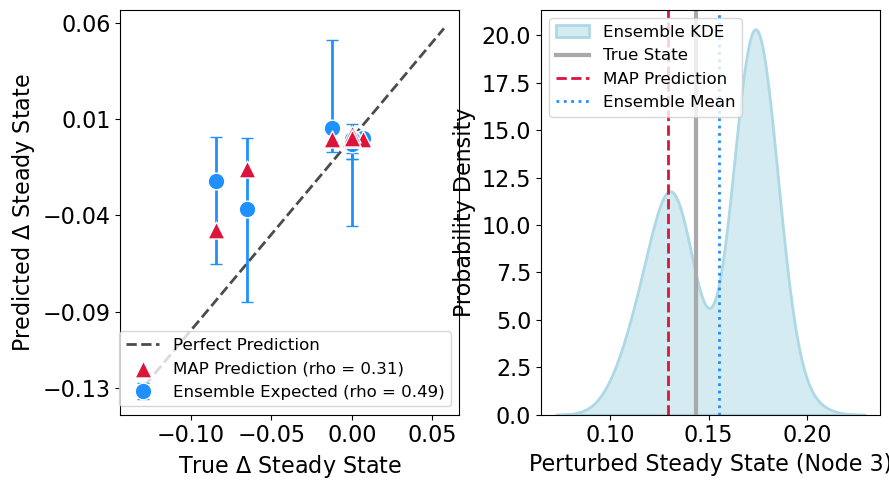

In [27]:

from scipy.integrate import odeint
from scipy.stats import spearmanr

def wc_deriv(x, t, W, I_ext, tau_val):
    net_input = W @ x + I_ext
    # Ensure dimensions match
    return -x / tau_val + (1 - x) * expit(net_input)

t_span = np.linspace(0, 100, 500)
x0 = np.full(N, 0.5)

# Unperturbed I
I_ext_unpert = np.full(N, I)

# Perturbed I (Overexpress node 0)
ko_idx = 0
I_ext_pert = I_ext_unpert.copy()
I_ext_pert[ko_idx] += 5.0

# 1. True system response
true_unpert_traj = odeint(wc_deriv, x0, t_span, args=(W_true, I_ext_unpert, tau))
true_unpert = true_unpert_traj[-1]

true_pert_traj = odeint(wc_deriv, true_unpert, t_span, args=(W_true, I_ext_pert, tau))
true_pert = true_pert_traj[-1]
delta_true = true_pert - true_unpert

# 2. Ensemble prediction
N_ens = len(W_ensemble)
delta_inferred = np.zeros((N_ens, N))
stat_inferred_pert = np.zeros((N_ens, N))

for i, W_s in enumerate(W_ensemble):
    # For inference, the tau parameter is absorbed in theta. 
    # But wait, in the notebook, theta_ensemble is also collected. 
    # Let's use the tau from theta_ensemble[i].
    # theta[0] = log(1/tau) -> tau = exp(-theta[0])
    tau_s = np.exp(-theta_ensemble[i][0])
    
    unpert_traj = odeint(wc_deriv, x0, t_span, args=(W_s, I_ext_unpert, tau_s))
    unpert_ss = unpert_traj[-1]
    
    pert_traj = odeint(wc_deriv, unpert_ss, t_span, args=(W_s, I_ext_pert, tau_s))
    pert_ss = pert_traj[-1]
    
    stat_inferred_pert[i] = pert_ss
    delta_inferred[i] = pert_ss - unpert_ss

mean_delta_inf = delta_inferred.mean(axis=0)

# 3. MAP prediction (we use the last sample, which was assigned to W_inferred)
best_idx = -1
best_delta_inf = delta_inferred[best_idx]

# Mask the perturbed node for evaluation
mask = np.ones(N, dtype=bool)
mask[ko_idx] = False

spearman_best, _ = spearmanr(delta_true[mask], best_delta_inf[mask])
spearman_ens, _ = spearmanr(delta_true[mask], mean_delta_inf[mask])

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(9, 5))
fontsize = 16

min_val = min(delta_true[mask].min(), mean_delta_inf[mask].min(), best_delta_inf[mask].min()) - 0.05
max_val = max(delta_true[mask].max(), mean_delta_inf[mask].max(), best_delta_inf[mask].max()) + 0.05

# Panel A: Scatter Plot
ax = axes[0]
ax.set_xlabel(r"True $\Delta$ Steady State", fontsize=fontsize)
ax.set_ylabel(r"Predicted $\Delta$ Steady State", fontsize=fontsize)
ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, alpha=0.7, label="Perfect Prediction")

ax.scatter(delta_true[mask], best_delta_inf[mask], color='crimson', s=150, edgecolor='white', 
           label=f"MAP Prediction (rho = {spearman_best:.2f})", marker='^', zorder=3)

lower_bound = np.percentile(delta_inferred, 2.5, axis=0)
upper_bound = np.percentile(delta_inferred, 97.5, axis=0)
yerr = [mean_delta_inf - lower_bound, upper_bound - mean_delta_inf]
yerr = [
    np.maximum(mean_delta_inf - lower_bound, 0),
    np.maximum(upper_bound - mean_delta_inf, 0),
]
ax.errorbar(delta_true[mask], mean_delta_inf[mask], yerr=[yerr[0][mask], yerr[1][mask]],
            fmt='o', color='dodgerblue', ecolor='dodgerblue', elinewidth=2, capsize=4,
            markersize=12, markeredgecolor='white', label=f"Ensemble Expected (rho = {spearman_ens:.2f})", zorder=2)

#ax.set_xlabel(r"True $\Delta$ Steady State")
#ax.set_ylabel(r"Predicted $\Delta$ Steady State")
#ax.set_title("Systemic Shift Prediction: MAP vs Ensemble", fontsize=fontsize)
ax.legend(loc="lower right", fontsize=fontsize-4)
ax.tick_params(axis='both', which='major', labelsize=fontsize)
ax.set_yticks(np.round(np.linspace(min_val, max_val, 5), 2))

# Panel B: KDE Density for a target node
# Find a node (other than ko_idx) with the largest true shift
target_node = np.argmax(np.abs(delta_true * mask))
ax = axes[1]
sns.kdeplot(stat_inferred_pert[:, target_node], ax=ax, fill=True, color='lightblue', alpha=0.5, lw=2, label="Ensemble KDE")

ax.axvline(true_pert[target_node], color='darkgray', linestyle='-', lw=3, label=f"True State")
ax.axvline(stat_inferred_pert[best_idx, target_node], color='crimson', linestyle='--', lw=2, label="MAP Prediction")
ax.axvline(stat_inferred_pert[:, target_node].mean(), color='dodgerblue', linestyle=':', lw=2, label="Ensemble Mean")

ax.set_xlabel(f"Perturbed Steady State (Node {target_node})", fontsize=fontsize)
ax.set_ylabel("Probability Density", fontsize=fontsize)
#ax.set_title(f"Resolving Uncertainty with Ensembles (Node {target_node})", fontsize=fontsize)
ax.legend(loc="upper left", fontsize=fontsize-4)
ax.tick_params(axis='both', which='major', labelsize=fontsize)

plt.tight_layout()
